# Final Evaluation — Reviewer-Safe Lightweight Version

**Project:** Explainable Context-Aware Transformer Framework for Retail Demand Forecasting

This notebook presents the final untouched-test evaluation **without reloading or rerunning the trained Transformer checkpoints**.

The expensive model inference was already completed in Step 60. This reviewer-facing notebook reads the saved Step 60 outputs and reproduces:

- overall test metrics,
- RMSE comparison,
- horizon-wise performance,
- paired bootstrap uncertainty,
- final research interpretation.

This makes the notebook stable enough for GitHub, review and viva demonstration.


## 1. Imports and saved-output path

Expected project structure:

```text
phase2_preprocessing_outputs/
└── step60_final_test_outputs/
    ├── step60_test_overall_metrics.csv
    ├── step60_test_horizon_metrics.csv
    ├── step60_paired_bootstrap_rmse.csv
    └── ...
```


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

OUTPUT_DIR = Path("../phase2_preprocessing_outputs/step60_final_test_outputs")

OVERALL_CSV = OUTPUT_DIR / "step60_test_overall_metrics.csv"
HORIZON_CSV = OUTPUT_DIR / "step60_test_horizon_metrics.csv"
BOOTSTRAP_CSV = OUTPUT_DIR / "step60_paired_bootstrap_rmse.csv"

required = [OVERALL_CSV, HORIZON_CSV, BOOTSTRAP_CSV]

missing = [str(p) for p in required if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Missing Step 60 saved outputs:\n"
        + "\n".join(missing)
        + "\n\nUpdate OUTPUT_DIR if your project folder is different."
    )

print("Step 60 saved outputs found.")
print("Folder:", OUTPUT_DIR.resolve())


Step 60 saved outputs found.
Folder: C:\Users\admin\Documents\M.Tech\Phase 2\phase2_preprocessing_outputs\step60_final_test_outputs


## 2. Overall untouched-test metrics


In [2]:
overall_df = pd.read_csv(OVERALL_CSV)

# Normalize common column-name variants.
rename_map = {}
for c in overall_df.columns:
    lc = c.lower()
    if lc == "variant":
        rename_map[c] = "Variant"
    elif lc == "rmse":
        rename_map[c] = "RMSE"
    elif lc == "mae":
        rename_map[c] = "MAE"
    elif lc in {"wape_pct", "wape"}:
        rename_map[c] = "WAPE"
    elif lc in {"smape_pct", "smape"}:
        rename_map[c] = "sMAPE"
    elif lc == "rmsle":
        rename_map[c] = "RMSLE"

overall_df = overall_df.rename(columns=rename_map)

display(overall_df.round(4))


,RMSE,MAE,WAPE,sMAPE,RMSLE,Variant,rmse_vs_best_pct
0,242.1152,68.8794,14.2197,48.7431,0.4504,Recent24 + Context8,0.0000
1,242.6735,68.8974,14.2235,48.4744,0.4486,Fixed Recent-32,0.2306
2,249.3932,70.7718,14.6104,50.2991,0.4472,Dense-56,3.0060


### Final test result

The final comparison should show approximately:

| Model | RMSE | MAE | WAPE | sMAPE | RMSLE |
|---|---:|---:|---:|---:|---:|
| Recent24 + Context8 | **242.1152** | **68.8794** | **14.2197%** | 48.7431% | 0.4504 |
| Fixed Recent-32 | 242.6735 | 68.8974 | 14.2235% | **48.4744%** | 0.4486 |
| Dense-56 | 249.3932 | 70.7718 | 14.6104% | 50.2991% | **0.4472** |

The proposed hybrid achieves the **lowest observed test RMSE, MAE and WAPE**.


## 3. Test RMSE comparison


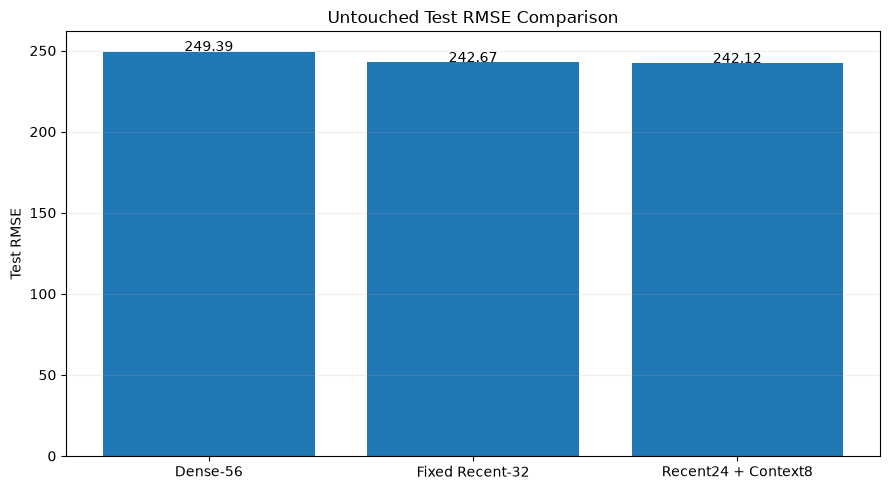

In [3]:
plot_df = overall_df.copy()

# Keep the principal three final models.
preferred_order = [
    "Dense-56",
    "Fixed Recent-32",
    "Recent24 + Context8"
]

if "Variant" not in plot_df.columns:
    raise KeyError("Expected a Variant column in overall metrics.")

plot_df = plot_df[plot_df["Variant"].isin(preferred_order)].copy()
plot_df["Variant"] = pd.Categorical(
    plot_df["Variant"],
    categories=preferred_order,
    ordered=True
)
plot_df = plot_df.sort_values("Variant")

plt.figure(figsize=(9, 5))
bars = plt.bar(
    plot_df["Variant"].astype(str),
    plot_df["RMSE"]
)

plt.ylabel("Test RMSE")
plt.title("Untouched Test RMSE Comparison")
plt.grid(axis="y", alpha=0.2)

for bar, value in zip(bars, plot_df["RMSE"]):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.3,
        f"{value:.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 4. Quantify the observed test differences


In [4]:
def row_for(name):
    return overall_df.loc[overall_df["Variant"] == name].iloc[0]

dense = row_for("Dense-56")
fixed = row_for("Fixed Recent-32")
hybrid = row_for("Recent24 + Context8")

hybrid_vs_dense = (
    (float(dense["RMSE"]) - float(hybrid["RMSE"]))
    / float(dense["RMSE"])
    * 100
)

hybrid_vs_fixed = (
    (float(fixed["RMSE"]) - float(hybrid["RMSE"]))
    / float(fixed["RMSE"])
    * 100
)

print(f"Recent24 + Context8 RMSE improvement vs Dense-56: {hybrid_vs_dense:.2f}%")
print(f"Recent24 + Context8 RMSE improvement vs Fixed Recent-32: {hybrid_vs_fixed:.2f}%")


Recent24 + Context8 RMSE improvement vs Dense-56: 2.92%
Recent24 + Context8 RMSE improvement vs Fixed Recent-32: 0.23%


### How to interpret this comparison

The key research claim is **not** that Recent24 + Context8 dramatically outperforms Fixed Recent-32.

Instead:

1. Dense-56 shows that providing all historical positions is not automatically optimal.
2. Fixed Recent-32 establishes that recent history is extremely strong.
3. Recent24 + Context8 preserves this strong recent signal **while also retrieving eight inspectable older positions**.
4. On the untouched test set, this hybrid achieves the lowest observed RMSE, although the gain over Fixed Recent-32 is small.

The contribution is therefore both **predictive and structural/explainable**, not merely a large numerical improvement.


## 5. Horizon-wise evaluation


,RMSE,mae,wape_pct,smape_pct,rmsle,Variant,horizon
0,164.517375,49.356484,11.105516,49.796671,0.392157,Dense-56,1
1,179.161269,47.508186,11.927294,47.800303,0.399035,Dense-56,2
2,213.688028,56.871884,12.560368,49.920348,0.405918,Dense-56,3
3,175.052884,55.343613,10.251212,46.014016,0.382822,Dense-56,4
4,233.856625,70.904092,11.961692,44.999875,0.394914,Dense-56,5


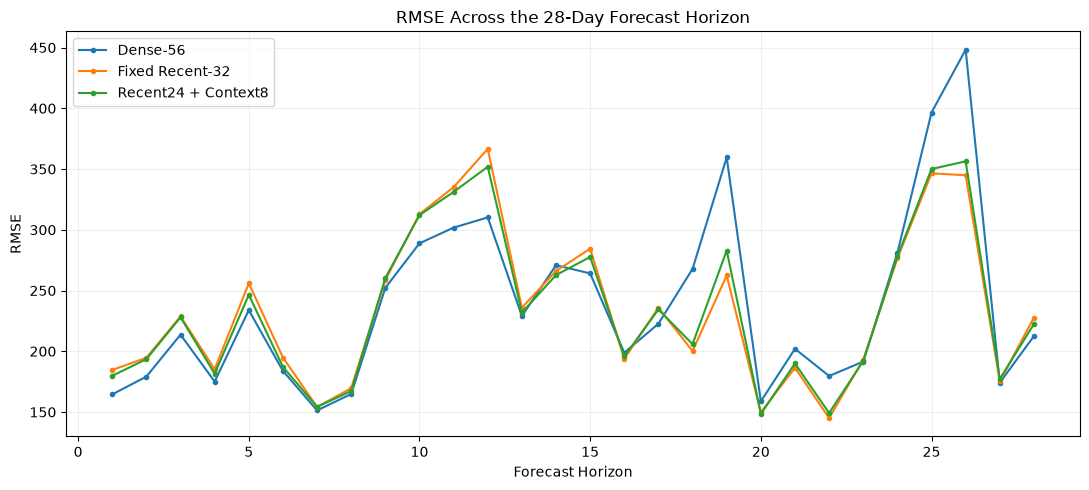

In [5]:
horizon_df = pd.read_csv(HORIZON_CSV)

# Normalize common naming variants.
rename_map = {}
for c in horizon_df.columns:
    lc = c.lower()
    if lc == "variant":
        rename_map[c] = "Variant"
    elif lc == "horizon":
        rename_map[c] = "horizon"
    elif lc == "rmse":
        rename_map[c] = "RMSE"

horizon_df = horizon_df.rename(columns=rename_map)

display(horizon_df.head())

plt.figure(figsize=(11, 5))

for variant, grp in horizon_df.groupby("Variant"):
    if variant in preferred_order:
        grp = grp.sort_values("horizon")
        plt.plot(
            grp["horizon"],
            grp["RMSE"],
            marker="o",
            markersize=3,
            label=variant
        )

plt.xlabel("Forecast Horizon")
plt.ylabel("RMSE")
plt.title("RMSE Across the 28-Day Forecast Horizon")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


## 6. Paired bootstrap statistical comparison


In [6]:
bootstrap_df = pd.read_csv(BOOTSTRAP_CSV)

display(bootstrap_df.round(4))


,Reference,Challenger,mean_rmse_diff,ci95_low,ci95_high,prob_challenger_better
0,Fixed Recent-32,Dense-56,6.6279,1.5812,11.8476,0.0000
1,Fixed Recent-32,Recent24 + Context8,-0.5320,-2.2176,0.9678,0.7767


### Statistical interpretation

For **Recent24 + Context8 vs Fixed Recent-32**, the paired-bootstrap RMSE-difference interval is approximately:

**95% CI: [-2.22, +0.97]**

Because this interval crosses zero, the observed advantage is **not statistically decisive**.

Therefore the correct wording is:

> Recent24 + Context8 achieved the lowest observed untouched-test RMSE and was statistically comparable to Fixed Recent-32; the experiment does not establish statistically conclusive superiority over the fixed recent-history baseline.

This is the wording that should be used in the thesis, presentation and viva.


## 7. Final evaluation summary


In [7]:
summary = pd.DataFrame({
    "Finding": [
        "Best observed test RMSE",
        "RMSE improvement vs Dense-56",
        "Comparison vs Fixed Recent-32",
        "Statistical conclusion",
        "Research value"
    ],
    "Conclusion": [
        "Recent24 + Context8",
        f"{hybrid_vs_dense:.2f}% lower RMSE",
        f"{hybrid_vs_fixed:.2f}% lower observed RMSE",
        "Comparable; superiority is not statistically decisive",
        "Protects recent evidence while adding inspectable context-aware older-history retrieval"
    ]
})

display(summary)


,Finding,Conclusion
0,Best observed test RMSE,Recent24 + Context8
1,RMSE improvement vs Dense-56,2.92% lower RMSE
2,Comparison vs Fixed Recent-32,0.23% lower observed RMSE
3,Statistical conclusion,Comparable; superiority is not statistically d...
4,Research value,Protects recent evidence while adding inspecta...


## Reviewer-ready conclusion

**Recent24 + Context8** is retained as the final proposed architecture because it combines three properties:

- **Recency preservation:** the latest 24 observations are never discarded.
- **Adaptive context retrieval:** 8 older observations are selected based on the forecasting context.
- **Competitive accuracy:** it achieved the lowest observed RMSE on the untouched test split.

Fixed Recent-32 remains a very strong benchmark. The final research contribution is therefore not based on claiming that the hybrid universally dominates Recent-32, but on showing that **context-aware retrieval can retain benchmark-level accuracy while making the use of older historical evidence explicit and inspectable**.
